# 02 — Une validation qui ressemble au test caché

**Objectif du notebook.** Avant de construire le moindre modèle, il faut un moyen fiable de savoir si une idée améliore vraiment le score. On ne peut pas compter sur le leaderboard public : 5 soumissions par jour, ~130 molécules seulement, et un bruit d'environ ±0.006 d'une soumission à l'autre.

On construit donc ici trois outils, réutilisés par tous les notebooks suivants :

1. **La clé du score** (`scorer_key`) : la façon exacte dont Kaggle décide si deux structures sont « la même réponse ».
2. **La métrique locale** MRR@25, identique à celle de Kaggle.
3. **Un jeu de validation** construit pour ressembler au test caché : des produits naturels dont **aucun** spectre n'est visible par le modèle.

Les fonctions réutilisables sont dans [`casmi.py`](casmi.py). Le notebook les appelle et montre ce qu'elles font.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import casmi

pd.set_option("display.width", 140)

## 1. Charger les métadonnées, sans les spectres

Le fichier `train.parquet` pèse 3 Go, presque entièrement à cause des tableaux de pics (`ms2_mzs`, `ms2_normalized_intensities`). Pour construire la validation, on n'a besoin que des colonnes descriptives. On les charge seules : environ 0,75 Go en mémoire et 2 secondes, contre plusieurs minutes et ~7 Go pour le fichier entier.

L'index de ce DataFrame (0, 1, 2…) est le **numéro de ligne dans le fichier**. On s'en servira pour aller chercher les spectres plus tard.

In [2]:
meta = casmi.load_train_meta()
print(meta.shape)
print(f"{meta.memory_usage(deep=True).sum() / 1e9:.2f} Go en mémoire")
meta.head(3)

(2539608, 12)


0.75 Go en mémoire


,ingest_lib,normalized_smiles,inchikey14,molecular_formula,ionization_mode,instrument_type,adduct,precursor_mz,precursor_error_ppm,num_peaks,base_peak_intensity,collision_energy_ev
0,drug_plus,O=C1NC(=O)c2cc(Nc3ccccc3)c(Nc3ccccc3)cc21,AAALVYBICLMAMA,C20H15N3O2,positive,NaN,[M+H]+,330.1237,1.671398,52,NaN,None
1,drug_plus,C#Cc1cccc(Nc2ncnc3cc(OCCOC)c(OCCOC)cc23)c1,AAKJLRGGTJKAMG,C22H23N3O4,positive,NaN,[M+K]+,432.1320,1.302193,28,NaN,None
2,drug_plus,CC1(C)CCC(C)(C)c2cc(C(O)C(O)=Nc3ccc(C(=O)O)cc3...,AANFHDFOMFRLLR,C23H26FNO4,positive,NaN,[M+Na]+,422.1738,1.316437,41,NaN,None


## 2. La clé du score

Kaggle ne compare pas les SMILES en tant que texte. Pour chaque proposition, il fait :

1. `SMILES → molécule` (RDKit) ;
2. **canonisation des tautomères** : certaines molécules existent sous plusieurs formes qui ne diffèrent que par la position d'un hydrogène (par exemple céto/énol). RDKit choisit une forme de référence unique ;
3. calcul de l'InChIKey, dont on garde **les 14 premiers caractères** : ils décrivent la connectivité des atomes, sans la stéréochimie.

Deux propositions qui donnent la même clé sont **la même réponse** pour le score. Ça a deux conséquences :
- les 25 propositions d'une molécule doivent avoir 25 clés **différentes**, sinon on gaspille des places ;
- pour regrouper les spectres d'une même molécule, il faut utiliser cette clé, **pas** la colonne `inchikey14` fournie, qui n'est pas canonisée.

La fonction `casmi.scorer_key` reproduit le code officiel ([notebook de la métrique](https://www.kaggle.com/code/metric/casmi-mean-reciprocal-rank)), avec la même version de RDKit (2026.03.3).

**Note** : les `inchikey` présentes dans les dataset ont donc une granularité plus fine 
que les clés que nous calculons. La clé recalculée proprement en repartant de la molécule 
et en veillant à l'unicité "à un tautomère près" permet de reconstituer la véritable clé 
utilisée pour l'évaluation.

In [3]:
import rdkit
print("RDKit", rdkit.__version__)

# Glucose : avec ou sans stéréochimie, même clé (exemple de la page Evaluation)
print(casmi.scorer_key("OC[C@H]1OC(O)[C@H](O)[C@@H](O)[C@@H]1O"))
print(casmi.scorer_key("OCC1OC(O)C(O)C(O)C1O"))

# Tautomères : 2-hydroxypyridine et 2-pyridone sont deux écritures de la même réponse
print(casmi.scorer_key("Oc1ccccn1"), casmi.scorer_key("O=c1cccc[nH]1"))

RDKit 2026.03.3
WQZGKKKJIJFFOK
WQZGKKKJIJFFOK
UBQKCCHYAOITMY UBQKCCHYAOITMY


On calcule la clé (plus la formule brute et la masse exacte) pour chacune des ~277 000 structures du train. C'est lent : environ 10 ms par structure, donc environ 8 minutes sur 7 cœurs en parallèle. Le résultat est enregistré dans `data/processed/structures.parquet` : les fois suivantes, il est simplement relu.

In [4]:
structures = casmi.structure_table(meta)
print(structures.shape)
print("SMILES illisibles :", structures["key"].isna().sum())
structures.head()

(277566, 4)
SMILES illisibles : 0


,normalized_smiles,key,formula,exact_mass
0,CN,BAVYZALUXZFZLV,CH5N,31.042199
1,NO,AVXURJPOCDRRFD,H3NO,33.021464
2,CO,OKKJLVBELUTLKV,CH4O,32.026215
3,CCN,QUSNBJAOOMFDIB,C2H7N,45.057849
4,CNC,ROSDSFDQCJNGOL,C2H7N,45.057849


In [5]:
# On ajoute la clé du score à chaque spectre
smiles_to = structures.set_index("normalized_smiles")
meta["key"] = meta["normalized_smiles"].map(smiles_to["key"])
meta["exact_mass"] = meta["normalized_smiles"].map(smiles_to["exact_mass"])

# Combien de fois la colonne fournie inchikey14 diffère-t-elle de la vraie clé du score ?
per_smiles = meta.drop_duplicates("normalized_smiles")[["inchikey14", "key"]]
diff = (per_smiles["inchikey14"] != per_smiles["key"]).mean()
print(f"Structures dont inchikey14 fourni ≠ clé du score : {diff:.1%}")
print(f"inchikey14 distincts : {meta['inchikey14'].nunique():,}")
print(f"clés du score distinctes : {meta['key'].nunique():,}")

Structures dont inchikey14 fourni ≠ clé du score : 1.6%
inchikey14 distincts : 275,810
clés du score distinctes : 274,195


## 3. La métrique MRR@25 locale

Pour chaque molécule, on regarde le rang de la **première** proposition correcte parmi les 25 : elle rapporte `1/rang` (1 au rang 1, 0,5 au rang 2… 0,04 au rang 25), et 0 si la bonne réponse n'y est pas. Le score final est la moyenne sur les molécules.

`casmi.mrr_at_25` travaille directement sur des clés déjà calculées : c'est beaucoup plus rapide que de recanoniser à chaque évaluation. On vérifie qu'elle redonne les exemples officiels de la métrique.

In [6]:
k = casmi.scorer_key
truth = {"m_1": k("CCO"), "m_2": k("c1ccccc1")}

# Exemple officiel 1 : éthanol au rang 1 (1.0), benzène au rang 2 (0.5) -> 0.75
pred = {"m_1": [k("CCO"), k("CC(=O)O")], "m_2": [k("CC(=O)O"), k("c1ccccc1")]}
print(casmi.mrr_at_25(pred, truth))

# Exemple officiel 2 : m_1 raté (0), m_2 trouvé au rang 1 (1) -> 0.5
pred = {"m_1": [k("CC(=O)O")], "m_2": [k("c1ccccc1")] * 3}
print(casmi.mrr_at_25(pred, truth))

# Stéréochimie ignorée -> 1.0
print(casmi.mrr_at_25({"m": [k("CC(N)C(=O)O")]}, {"m": k("C[C@H](N)C(=O)O")}))

0.75
0.5
1.0


## 4. Du plus simple au plus réaliste

La validation la plus simple consiste à cacher **un** spectre d'une molécule et à le chercher parmi ses **autres** spectres. C'est une bonne première étape pour mettre en place la méthode, mais elle mesure la *recherche en bibliothèque* d'une molécule déjà connue, c'est-à-dire la classe 1 du test. D'après les sondages du forum, celle-ci ne représente qu'environ 16 % du test caché.

Le vrai test contient surtout des molécules **dont aucun spectre n'existe** dans les bibliothèques publiques (classes 2 et 3). Et il faut faire attention à l'instrument : restreindre le train au timsTOF, l'instrument du test, revient en pratique à ne garder que `enveda-180`, c'est-à-dire de la chimie de synthèse type médicament, alors que le test contient des produits naturels.

La table ci-dessous le montre : sur timsTOF, presque tout vient de `enveda-180`.

In [7]:
tims = meta["instrument_type"] == "timsTOF"
meta.loc[tims, "ingest_lib"].value_counts()

ingest_lib
enveda-180            1153785
enveda-np-examples       1184
Name: count, dtype: int64

## 5. Construire le jeu de validation

**Le principe.** On choisit des molécules et on retire **tous** leurs spectres, **de toutes les bibliothèques**, en les identifiant par la clé du score. Le modèle ne verra jamais ces spectres comme références : il devra retrouver la structure autrement, comme pour une molécule des classes 2 et 3.

Si on retire seulement une bibliothèque, la même molécule reste présente ailleurs. C'est le piège décrit sur le forum : les 250 structures de `enveda-np-examples` ont environ 55 000 spectres dans les autres bibliothèques.

On construit deux sous-ensembles, qu'on évaluera **séparément** :

| Sous-ensemble | Molécules | Spectres requêtes | Intérêt | Limite |
|---|---|---|---|---|
| **A — np_examples** | les 250 de `enveda-np-examples` | leurs spectres timsTOF Enveda | même instrument et même traitement que le test caché | petit, donc bruité |
| **B — np_public** | 1 000 produits naturels tirés au hasard | ceux d'**une** source publique, QTOF de préférence | plus de molécules, donc une mesure plus stable | autres instruments que le test |

Ce double jeu vient d'une contrainte : **le test caché contient des produits naturels mesurés sur timsTOF, et presque aucune donnée publique ne réunit les deux**. Hors `enveda-np-examples`, tous les spectres timsTOF du train viennent de `enveda-180`, qui est de la chimie de synthèse. On ne peut pas non plus utiliser le `test.parquet` visible : ce sont des copies de lignes de `enveda-180`.

Ces molécules servent à **mesurer**, pas à apprendre. Pour l'entraînement et la recherche, on garde tout le reste du train, molécules de synthèse comprises : les règles de fragmentation sont en partie universelles.

Pour B, on garde des structures :
- présentes dans les bibliothèques publiques, **absentes** de `enveda-180` et `drug_plus` (chimie de médicament) ;
- dans la gamme de masse du test (157 à 1 159 Da) ;
- **présentes dans COCONUT**, la base publique de produits naturels. C'est la définition même de la classe 2 (« structure connue dans PubChem ou COCONUT, sans spectre public »). Sans ce filtre, B contiendrait beaucoup de molécules de synthèse issues des chimiothèques commerciales.

Pour ce filtre, une correspondance sur `inchikey14` suffit. Recalculer la clé du score pour les ~740 000 entrées de COCONUT prendrait plus d'une heure, et ce n'est utile qu'au moment de construire les candidats.

In [8]:
coconut = casmi.load_coconut()
coconut_ik14 = set(coconut["inchikey14"])
print(f"COCONUT : {len(coconut):,} entrées, {len(coconut_ik14):,} squelettes distincts")

COCONUT : 738,827 entrées, 479,721 squelettes distincts


In [9]:
# Tableau clé × bibliothèque : nombre de spectres de chaque structure dans chaque bibliothèque
lib_counts = pd.crosstab(meta["key"], meta["ingest_lib"])
key_mass = meta.groupby("key")["exact_mass"].first()
print(lib_counts.shape)
lib_counts.sum().sort_values(ascending=False)

(274195, 11)


ingest_lib
enveda-180            1153785
pluskal_ms2            527581
riken                  347171
gnps                   220849
massbank               101727
mona                    92416
spectraverse            50933
msdial                  40765
drug_plus                2545
enveda-np-examples       1184
masaryk                   652
dtype: int64

In [10]:
RNG_SEED = 42
N_PUBLIC = 1000

# A : les structures de enveda-np-examples
keys_a = lib_counts.index[lib_counts["enveda-np-examples"] > 0]

# B : produits naturels des bibliothèques publiques
np_libs = ["riken", "gnps", "massbank", "mona", "spectraverse", "msdial", "pluskal_ms2", "masaryk"]
eligible_b = (
    (lib_counts[np_libs].sum(axis=1) > 0)
    & (lib_counts["enveda-180"] == 0)
    & (lib_counts["drug_plus"] == 0)
    & (lib_counts["enveda-np-examples"] == 0)
    & key_mass.reindex(lib_counts.index).between(157, 1159)
)

# Présence dans COCONUT (via inchikey14 fourni, pour chaque clé du score)
key_to_ik14 = meta.drop_duplicates("key").set_index("key")["inchikey14"]
in_coconut = key_to_ik14.reindex(lib_counts.index).isin(coconut_ik14)
print(f"Éligibles avant filtre COCONUT : {eligible_b.sum():,}")
eligible_b &= in_coconut

# Il faut au moins un spectre avec un adduit du test et un précurseur cohérent
usable = meta["adduct"].isin(casmi.TEST_ADDUCTS) & (meta["precursor_error_ppm"].abs() < 10)
keys_with_usable = set(meta.loc[usable & meta["ingest_lib"].isin(np_libs), "key"])
candidates_b = [k for k in lib_counts.index[eligible_b] if k in keys_with_usable]

rng = np.random.default_rng(RNG_SEED)
keys_b = pd.Index(rng.choice(candidates_b, size=N_PUBLIC, replace=False))

print(f"A : {len(keys_a)} structures")
print(f"B : {len(keys_b)} tirées parmi {len(candidates_b):,} éligibles")

Éligibles avant filtre COCONUT : 86,295


A : 250 structures
B : 1000 tirées parmi 21,134 éligibles


**Les spectres requêtes.** Ce sont les spectres que le modèle recevra en entrée, comme s'ils venaient du test :

- pour A : les spectres de `enveda-np-examples`, mesurés sur timsTOF ;
- pour B : pour chaque molécule, les spectres d'**une seule source**, c'est-à-dire un couple *(bibliothèque, famille d'instrument)*. Une molécule du test vient d'une seule campagne de mesure, pas d'un mélange de laboratoires. Une bibliothèque seule ne suffit pas à définir une campagne : GNPS, par exemple, mélange Orbitrap, QTOF et ToF.

**Quelle source choisir pour B ?** Trois critères, dans l'ordre :

1. **au moins 2 spectres** dans la source. Sans ce critère, un tiers des molécules de B n'aurait qu'un seul spectre, contre 14 % dans le test. Exiger 3 spectres n'apporte rien de plus : les molécules restantes n'ont qu'un spectre, toutes sources confondues ;
2. **la famille d'instrument la plus proche du timsTOF**, dans cet ordre (`casmi.INSTRUMENT_PRIORITY`) :
   - **QTOF** : même architecture que le timsTOF, qui est lui-même un QTOF avec en plus une séparation par mobilité ionique. Fragmentation par collisions dans une cellule, énergies en eV comparables ;
   - **Orbitrap** : fragmentation HCD, de principe voisin, mais énergies exprimées sur une autre échelle (NCE) ;
   - **QqQ** (triple quadripôle) : fragmentation voisine, mais faible précision en masse ;
   - **piège à ions** : fragmentation de nature différente ;
3. **au hasard** entre sources ex aequo. Prendre systématiquement la plus fournie favoriserait les bibliothèques qui mesurent beaucoup d'énergies par molécule, comme `pluskal_ms2`, entièrement sur Orbitrap.

L'ordre des familles est un choix de principe, pas encore une mesure : on pourra le vérifier en comparant les spectres timsTOF de A aux spectres des mêmes molécules, famille par famille.

Dans tous les cas, on ne garde que les adduits du test et les précurseurs cohérents avec la structure (erreur < 10 ppm).

In [11]:
val_keys = keys_a.union(keys_b)
subset = pd.Series("B_np_public", index=val_keys)
subset[keys_a] = "A_np_examples"

q = meta[meta["key"].isin(val_keys) & usable].copy()
q["subset"] = q["key"].map(subset)
q["instrument_family"] = casmi.instrument_family(q["instrument_type"])
q["source"] = q["ingest_lib"] + " / " + q["instrument_family"]

# A : uniquement les spectres enveda-np-examples (timsTOF)
q_a = q[(q["subset"] == "A_np_examples") & (q["ingest_lib"] == "enveda-np-examples")]

# B : une seule source (bibliothèque, famille d'instrument) par molécule. Ordre de préférence :
#   1. une source d'au moins 2 spectres (sinon trop de molécules n'auraient qu'un spectre)
#   2. la famille d'instrument la plus proche du timsTOF
#   3. au hasard parmi les ex aequo
q_b = q[(q["subset"] == "B_np_public") & q["ingest_lib"].isin(np_libs)]
priority = {family: i for i, family in enumerate(casmi.INSTRUMENT_PRIORITY)}

sources = q_b.groupby(["key", "source", "instrument_family"]).size().reset_index(name="n_spectra")
sources["too_small"] = (sources["n_spectra"] < 2).astype(int)
sources["family_rank"] = sources["instrument_family"].map(priority)
chosen = (
    sources.sample(frac=1, random_state=RNG_SEED)                    # ordre aléatoire pour les ex aequo
    .sort_values(["too_small", "family_rank"], kind="stable")        # tri stable : garde cet ordre aléatoire
    .drop_duplicates("key")
    .set_index("key")["source"]
)
q_b = q_b[q_b["source"] == q_b["key"].map(chosen)]

val_queries = pd.concat([q_a, q_b])
val_queries.index.name = "row"

# Identifiants anonymes, comme dans le test
mol_ids = {key: f"v_{i:04d}" for i, key in enumerate(sorted(val_queries["key"].unique()))}
val_queries["molecule_id"] = val_queries["key"].map(mol_ids)

print(val_queries.groupby("subset").agg(molecules=("key", "nunique"), spectres=("key", "size")))
print()
print("B : famille d'instrument des requêtes (en molécules)")
print(val_queries[val_queries["subset"] == "B_np_public"].drop_duplicates("key")["instrument_family"].value_counts())

               molecules  spectres
subset                            
A_np_examples        250      1182
B_np_public         1000      7463

B : famille d'instrument des requêtes (en molécules)


instrument_family
QTOF        579
Orbitrap    365
IonTrap      26
other        22
QqQ           8
Name: count, dtype: int64


**Autant de spectres que dans le test.** Le test caché a 1 à 16 spectres par molécule, 3 en médiane. Nos molécules de validation en ont souvent beaucoup plus. Or plus de spectres donne plus d'information et gonfle artificiellement le score. `casmi.sample_queries` tire donc, pour chaque molécule, un nombre de spectres selon la distribution observée dans le fichier de test, et on moyennera les résultats sur plusieurs tirages (graines 0 à 4).

Piège (signalé sur le forum) : si on tire k puis qu'on le plafonne au nombre de spectres disponibles, la moyenne baisse (2,45 au lieu de 3). On tire donc k **parmi les valeurs réalisables** pour chaque molécule. Les molécules qui n'ont qu'un ou deux spectres gardent tout ce qu'elles ont.

In [12]:
counts = casmi.spectra_count_distribution()
print("Test : spectres par molécule, moyenne", counts.mean().round(2), "| médiane", np.median(counts))

available = val_queries.groupby("molecule_id").size()
print("Validation avant tirage : moyenne", available.mean().round(2), "| médiane", available.median())

for seed in range(5):
    draw = casmi.sample_queries(val_queries, counts, seed)
    print(f"  tirage {seed} : {len(draw):,} spectres, {draw.groupby('molecule_id').size().mean():.2f} par molécule")

Test : spectres par molécule, moyenne 3.03 | médiane 3.0
Validation avant tirage : moyenne 6.92 | médiane 4.0


  tirage 0 : 2,748 spectres, 2.20 par molécule


  tirage 1 : 2,859 spectres, 2.29 par molécule


  tirage 2 : 2,762 spectres, 2.21 par molécule


  tirage 3 : 2,802 spectres, 2.24 par molécule


  tirage 4 : 2,776 spectres, 2.22 par molécule


**Pourquoi la moyenne reste sous 3 ?** La cellule suivante compare les distributions. Dans B, environ un quart des molécules n'ont qu'**un seul** spectre disponible, contre 14 % dans le test, et on ne peut pas leur en inventer. C'est aussi le prix de la préférence pour les sources QTOF, souvent plus petites. L'écart est structurel : notre validation est un peu **plus difficile** que le test, c'est-à-dire prudente.

Ce n'est pas un problème pour notre usage. On compare des variantes du pipeline **entre elles**, toujours avec les mêmes tirages. Le score absolu en validation ne se traduira de toute façon pas directement en score au classement.

In [13]:
test_dist = pd.Series(counts).value_counts(normalize=True).sort_index()
avail = val_queries.groupby(["subset", "molecule_id"]).size().clip(upper=10)
comparison = pd.DataFrame({
    "test": test_dist,
    "A (disponibles)": avail["A_np_examples"].value_counts(normalize=True),
    "B (disponibles)": avail["B_np_public"].value_counts(normalize=True),
}).fillna(0).round(2)
comparison.index.name = "spectres (10 = 10 ou plus)"
comparison

,test,A (disponibles),B (disponibles)
spectres (10 = 10 ou plus),,,
1,0.14,0.12,0.24
2,0.24,0.19,0.16
3,0.25,0.11,0.11
4,0.26,0.14,0.09
5,0.06,0.14,0.06
6,0.04,0.05,0.07
7,0.00,0.04,0.02
8,0.00,0.05,0.05
9,0.00,0.06,0.02


## 6. Vérifications

Trois contrôles avant de sauvegarder :

1. **Aucune fuite.** La bibliothèque de référence (tous les spectres **hors** validation) ne doit contenir aucun spectre d'une molécule de validation, sous aucune écriture.
2. **Adduits et polarités** : on veut une répartition proche du test (surtout `[M+H]+` et `[M-H]-`).
3. **Masses** dans la gamme du test.

In [14]:
is_reference = ~meta["key"].isin(val_keys)
leak = meta.loc[is_reference, "key"].isin(set(val_queries["key"])).sum()
print("Spectres de validation restés dans la référence :", leak)
print(f"Référence : {is_reference.sum():,} spectres, {meta.loc[is_reference, 'key'].nunique():,} structures")
print(f"Retirés   : {(~is_reference).sum():,} spectres")

Spectres de validation restés dans la référence : 0


Référence : 2,456,709 spectres, 272,945 structures
Retirés   : 82,899 spectres


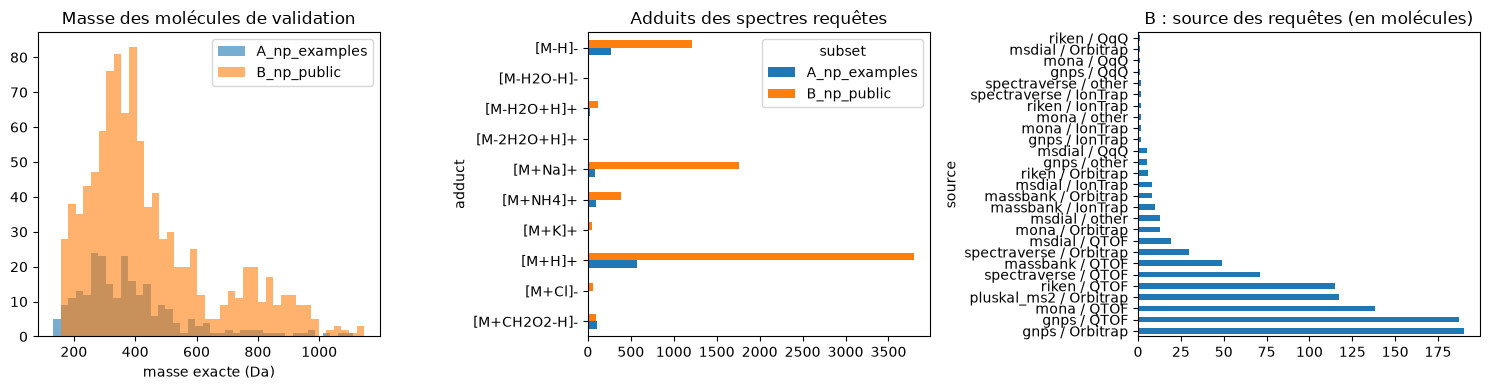

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for name, g in val_queries.groupby("subset"):
    axes[0].hist(g.drop_duplicates("key")["exact_mass"], bins=40, alpha=0.6, label=name)
axes[0].set(title="Masse des molécules de validation", xlabel="masse exacte (Da)")
axes[0].legend()

val_queries.groupby("subset")["adduct"].value_counts().unstack(0).fillna(0).plot.barh(ax=axes[1])
axes[1].set(title="Adduits des spectres requêtes")

b_sources = val_queries[val_queries["subset"] == "B_np_public"].drop_duplicates("key")["source"]
b_sources.value_counts().plot.barh(ax=axes[2])
axes[2].set(title="B : source des requêtes (en molécules)")
plt.tight_layout()
plt.show()

## 7. Sauvegarde

Trois fichiers dans `data/processed/`, relus par les notebooks suivants :

- `val_structures.parquet` : une ligne par molécule de validation (identifiant, clé, SMILES, formule, masse, sous-ensemble) ;
- `val_queries.parquet` : les spectres requêtes possibles (numéro de ligne dans `train.parquet` + métadonnées) ;
- `reference_rows.npy` : les numéros de ligne autorisés comme références, c'est-à-dire tout le train **sauf** les molécules de validation.

In [16]:
val_structures = (
    val_queries.drop_duplicates("key")[["molecule_id", "key", "normalized_smiles", "exact_mass", "subset"]]
    .merge(structures[["normalized_smiles", "formula"]], on="normalized_smiles", how="left")
    .sort_values("molecule_id")
    .reset_index(drop=True)
)
query_cols = ["molecule_id", "subset", "key", "ingest_lib", "instrument_family", "source", "adduct",
              "ionization_mode", "precursor_mz", "collision_energy_ev", "num_peaks", "base_peak_intensity"]

val_structures.to_parquet(casmi.paths.processed / "val_structures.parquet", index=False)
val_queries[query_cols].reset_index().to_parquet(casmi.paths.processed / "val_queries.parquet", index=False)
np.save(casmi.paths.processed / "reference_rows.npy", np.flatnonzero(is_reference.to_numpy()))

print(val_structures["subset"].value_counts())
val_structures.head()

subset
B_np_public      1000
A_np_examples     250
Name: count, dtype: int64


,molecule_id,key,normalized_smiles,exact_mass,subset,formula
0,v_0000,AAWZDTNXLSGCEK,O=C(O)C1(O)CC(O)C(O)C(O)C1,192.063388,A_np_examples,C7H12O6
1,v_0001,ACNHBCIZLNNLRS,CC(C)(O)C1OC2CCC3(C)C(O)(CCC4Cc5c([nH]c6ccccc5...,435.240959,A_np_examples,C27H33NO4
2,v_0002,ACSAKRLPJQIBFB,c1ccc(CCNCCc2ccccc2)cc1,225.151750,B_np_public,C16H19N
3,v_0003,ACWBQPMHZXGDFX,CCCCC(=O)N(Cc1ccc(-c2ccccc2-c2nn[nH]n2)cc1)C(C...,435.227040,A_np_examples,C24H29N5O3
4,v_0004,ADAGRLDCCJAKFP,COc1ccc(CCN(C)CCCN(C(=O)c2ccc([N+](=O)[O-])cc2...,537.247500,B_np_public,C29H35N3O7


## À retenir

- La clé du score regroupe les écritures équivalentes d'une même structure. On l'utilise partout à la place de `inchikey14`.
- **Vocabulaire :**
  - **spectres requêtes** : ceux qu'on donne au modèle comme s'ils venaient du test ;
  - **bibliothèque de référence** : les spectres de structure connue dans lesquels on cherche ;
  - **réservoir de candidats** : les structures qu'on a le droit de proposer (train ∪ COCONUT).
- Le jeu de validation contient 1 250 **produits naturels** : 250 mesurés sur timsTOF (A) et 1 000 venant des bibliothèques publiques, de préférence sur QTOF (B).
- **La classe n'est pas une propriété des molécules, mais de ce qu'on cache au modèle.** Les mêmes molécules s'évaluent dans trois conditions :

| Condition | Retiré de la bibliothèque de référence | Retiré du réservoir de candidats |
|---|---|---|
| Classe 1 | les spectres requêtes et ceux de la même source | rien |
| Classe 2 | **tous** les spectres de la molécule | rien |
| Classe 3 | **tous** les spectres de la molécule | la structure (par clé du score) |

- `reference_rows.npy` correspond à la condition classe 2. Les deux autres conditions seront construites par une fonction dans le notebook 03.
- **Prochaine étape (`03_library_search`)** : une vraie recherche par similarité spectrale (nettoyage des pics, similarité d'entropie, fenêtre de masse neutre), évaluée sur cette validation.